### Bibertomograph – Lösung Schritt für Schritt

*44. Bundeswettbewerb Informatik (2025), 1. Runde, Aufgabe 4*

Bei den jährlichen Biberland-Games werden in einer Disziplin aus der Luft sichtbare Figuren auf einer gerasterten Fläche
gestaltet. Ein Rasterfeld kann dabei entweder mit Holzspänen gefüllt sein oder nicht.

Die Fläche wird vor der Jurywertung den Blicken der neugierigen Biberazzi durch einen Bretterzaun entzogen. Biberazzo Azze
hat nun festgestellt, dass er durch kleine Lücken im Zaun senkrecht und diagonal über die Fläche schauen kann und aufgrund
der Helligkeit erahnt, wie viele gefüllte Felder auf seiner jeweiligen Sichtlinie liegen. Azze will unbedingt möglichst
viele Figuren bereits vorher herausfinden und versucht, durch logische Schlussfolgerungen und Ausprobieren die korrekten
Figuren zu rekonstruieren.

In der Vorrunde wurde auf 8 × 8-Flächen gespielt. Das Beispiel zeigt eines der Kunstwerke sowie die entsprechenden
Ergebnisse von Azzes Beobachtung entlang der waagerechten, senkrechten und diagonalen Sichtlinien.

Azze kennt natürlich nur seine Beobachtungen, nicht aber die entsprechende Figur. Er überlegt, ob er aufgrund der
horizontalen, vertikalen und diagonalen Summen wie in diesem Fall immer die tatsächliche Figur bestimmen kann. Die Zahl der
Rasterfelder wird in den Runden des Wettbewerbs immer größer. So werden nach der Vorrunde bereits 12 × 12-Flächen verschönert.

#### Aufgabe 4

Hilf Azze mit einem Programm, das für eine beliebige n × n-Fläche die Summen einliest und daraufhin eine dazu passende Figur
ausgibt. Falls sie nicht die einzig mögliche ist, sollte das Programm in der Figur die nicht eindeutigen Felder durch
Fragezeichen kennzeichnen.

Wende dein Programm mindestens auf alle Beispiele an, die du auf den BWINF-Webseiten findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `tomograph00.txt` (das Beispiel vom Aufgabenblatt, 8 × 8) bis `tomograph10.txt`. Jede Datei hat
fünf Zeilen:

1. die Größe `n`,
2. die Anzahl gefüllter Felder in jeder **Spalte**, von links nach rechts,
3. die Anzahl gefüllter Felder in jeder **Zeile**, von oben nach unten,
4. die Anzahl für jede **blaue** Diagonale (`2n − 1` Werte), von oben links bis unten rechts gelesen,
5. die Anzahl für jede **gelbe** Diagonale (`2n − 1` Werte), von unten links nach oben rechts gelesen.

```
8
1 1 5 6 5 1 2 1
3 2 3 2 6 2 2 2
0 0 1 3 2 3 3 1 2 3 1 2 0 1 0
0 0 1 0 4 2 1 3 5 3 2 1 0 0 0
```

Wie die Diagonalen genau verlaufen, verrät erst das kleine Beispiel aus der README: 2 × 2, Spalten `1 0`, Zeilen `0 1`, blau
`0 1 0`, gelb `1 0 0`. Die einzige Lösung ist ein gefülltes Feld **unten links**. Daraus folgt: Die **blauen** Linien verlaufen
wie „/“, die erste geht durch die Ecke oben links. Die **gelben** Linien verlaufen wie „\“, die erste geht durch die Ecke unten
links. Mit Zeile `r` und Spalte `c` (ab 0 gezählt) liegt ein Feld auf der blauen Linie Nummer `r + c` und auf der gelben Linie
Nummer `c − r + n − 1`.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Gute Modellierung:** Alle vier Arten von Sichtlinien (Zeilen, Spalten, zwei Sorten Diagonalen) werden gleich behandelt: Jede
  Linie ist eine **Liste von Feldern** mit einer **Soll-Anzahl** gefüllter Felder. Danach muss das Programm nicht mehr wissen,
  welche Art von Linie es gerade vor sich hat.
- **Drei Zustände pro Feld:** gefüllt (1), leer (0) und „noch offen“. In der Ausgabe kommt „nicht eindeutig“ (?) dazu.
- **Logisches Schließen (Constraint Propagation):** So macht es auch Azze. Braucht eine Linie keine weiteren gefüllten Felder
  mehr, sind ihre offenen Felder leer. Braucht sie genau so viele, wie noch offen sind, sind alle gefüllt. Das wiederholt man,
  bis sich nichts mehr ändert.
- **Backtracking mit Rekursion:** Hilft das Schließen nicht weiter, probiert man ein offenes Feld aus: erst gefüllt, und wenn das
  in eine Sackgasse führt, leer. Eine Funktion ruft sich dafür selbst mit dem kleineren Problem auf. Sackgassen erkennt man früh:
  Eine Linie hat mehr gefüllte Felder als erlaubt, oder es sind zu wenige offene Felder übrig.
- **Eindeutigkeit Feld für Feld:** Ein Feld ist eindeutig, wenn es in **allen** passenden Figuren gleich ist. Man prüft also für
  jedes Feld, ob es eine passende Figur mit diesem Feld gefüllt gibt und eine mit diesem Feld leer.
- **Ergebnisse wiederverwenden:** Jede gefundene Figur zeigt für **alle** Felder einen möglichen Wert. Merkt man sich diese,
  spart man sehr viele Suchen.

**Nützliche Funktionen und Bibliotheken**
- Listen von Listen, Tupel `(r, c)` für ein Feld, `set` für die möglichen Werte eines Feldes
- Kopie eines Rasters: `[zeile[:] for zeile in raster]` (sonst ändert man das Original mit)
- `matplotlib.pyplot` für die Zeichnung (optional)

## Die Idee

1. Die Summen einlesen und daraus alle Sichtlinien bauen: für jede die Liste ihrer Felder und die Soll-Anzahl.
2. **Logisch schließen**, solange etwas zu holen ist. Schon damit sind manche Beispiele vollständig gelöst.
3. Bleiben offene Felder, eins davon **ausprobieren** (erst gefüllt, dann leer), wieder schließen und so weiter (Backtracking).
   So findet man eine passende Figur, wenn es eine gibt.
4. Für die **Fragezeichen**: Für jedes Feld wird geprüft, ob es mit „gefüllt“ und ob es mit „leer“ eine passende Figur gibt. Gibt
   es beides, bekommt das Feld ein Fragezeichen. Jede gefundene Figur wird dabei für alle Felder vermerkt. Dadurch sind viele
   Prüfungen gar nicht mehr nötig.

## Schritt 1: Die Eingabe lesen

Jede nicht leere Zeile wird in eine Liste von Zahlen verwandelt. Die erste Zahl ist `n`, dann folgen die vier Listen.

In [ ]:
def lies_eingabe(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zeilen = []
        for zeile in f.read().splitlines():
            if zeile.split():                        # leere Zeilen überspringen
                zahlen = []
                for t in zeile.split():
                    zahlen.append(int(t))
                zeilen.append(zahlen)
    n = zeilen[0][0]
    return n, zeilen[1], zeilen[2], zeilen[3], zeilen[4]


n, spalten, zeilen, blau, gelb = lies_eingabe('beispieldaten/tomograph01.txt')
print('n =', n)
print('Spalten:', spalten, ' Zeilen:', zeilen, ' blau:', blau, ' gelb:', gelb)

n = 2
Spalten: [1, 0]  Zeilen: [0, 1]  blau: [0, 1, 0]  gelb: [1, 0, 0]


## Schritt 2: Die Sichtlinien

Jetzt bauen wir aus den vier Listen **eine** Liste `linien`. Jede Linie ist eine Liste von Feldern `(r, c)` (Zeile, Spalte).
Daneben steht in `soll` an derselben Position, wie viele davon gefüllt sein sollen.

- Spalte `c` enthält die Felder `(0, c)`, `(1, c)`, …, `(n−1, c)`.
- Zeile `r` enthält `(r, 0)`, …, `(r, n−1)`.
- Blaue Linie `d` enthält alle Felder mit `r + c == d`, also `(r, d − r)`, soweit die Spalte im Raster liegt.
- Gelbe Linie `d` enthält alle Felder mit `c − r + n − 1 == d`, also `(r, r + d − n + 1)`.

In [ ]:
def bilde_linien(n, spalten, zeilen, blau, gelb):
    linien = []
    soll = []
    for c in range(n):                          # Spalten
        linie = []
        for r in range(n):
            linie.append((r, c))
        linien.append(linie)
        soll.append(spalten[c])
    for r in range(n):                          # Zeilen
        linie = []
        for c in range(n):
            linie.append((r, c))
        linien.append(linie)
        soll.append(zeilen[r])
    for d in range(2 * n - 1):                  # blaue Diagonalen "/"
        linie = []
        for r in range(n):
            c = d - r
            if 0 <= c < n:
                linie.append((r, c))
        linien.append(linie)
        soll.append(blau[d])
    for d in range(2 * n - 1):                  # gelbe Diagonalen "\"
        linie = []
        for r in range(n):
            c = r + d - n + 1
            if 0 <= c < n:
                linie.append((r, c))
        linien.append(linie)
        soll.append(gelb[d])
    return linien, soll


linien, soll = bilde_linien(n, spalten, zeilen, blau, gelb)
for i in range(len(linien)):
    print(linien[i], 'soll', soll[i])

[(0, 0), (1, 0)] soll 1
[(0, 1), (1, 1)] soll 0
[(0, 0), (0, 1)] soll 0
[(1, 0), (1, 1)] soll 1
[(0, 0)] soll 0
[(0, 1), (1, 0)] soll 1
[(1, 1)] soll 0
[(1, 0)] soll 1
[(0, 0), (1, 1)] soll 0
[(0, 1)] soll 0


Zur Kontrolle eine Funktion, die prüft, ob eine **fertige** Figur zu allen Summen passt. Für das 2 × 2-Beispiel aus der README
ist die Figur mit dem gefüllten Feld unten links richtig, die mit dem Feld oben rechts nicht.

In [ ]:
def passt(figur, linien, soll):
    for i in range(len(linien)):
        anzahl = 0
        for r, c in linien[i]:
            anzahl = anzahl + figur[r][c]
        if anzahl != soll[i]:
            return False
    return True


print(passt([[0, 0], [1, 0]], linien, soll))
print(passt([[0, 1], [0, 0]], linien, soll))

True
False


## Schritt 3: Logisch schließen

Ein Raster enthält jetzt drei Werte: `1` (gefüllt), `0` (leer) und `OFFEN` (noch nicht bekannt, wir nehmen dafür `-1`). Für jede
Linie zählen wir die schon gefüllten Felder und die offenen Felder. `rest` ist die Zahl der gefüllten Felder, die der Linie noch
fehlen.

- Ist `rest` negativ oder größer als die Zahl der offenen Felder, ist das Raster **widersprüchlich**: Es kann keine passende Figur
  mehr geben. Die Funktion gibt dann `False` zurück.
- Ist `rest == 0`, müssen alle offenen Felder der Linie **leer** sein.
- Ist `rest` gleich der Zahl der offenen Felder, müssen alle **gefüllt** sein.

Weil jede Änderung neue Schlüsse in anderen Linien möglich macht, wiederholen wir das, bis in einem ganzen Durchgang nichts mehr
geändert wurde. Die Funktion verändert das Raster, das sie bekommt.

In [ ]:
OFFEN = -1


def schliesse(raster, linien, soll):
    geaendert = True
    while geaendert:
        geaendert = False
        for i in range(len(linien)):
            gefuellt = 0
            offen = []
            for r, c in linien[i]:
                if raster[r][c] == 1:
                    gefuellt = gefuellt + 1
                elif raster[r][c] == OFFEN:
                    offen.append((r, c))
            rest = soll[i] - gefuellt
            if rest < 0 or rest > len(offen):
                return False                            # Widerspruch
            if len(offen) > 0 and (rest == 0 or rest == len(offen)):
                if rest == 0:
                    wert = 0
                else:
                    wert = 1
                for r, c in offen:
                    raster[r][c] = wert
                geaendert = True
    return True


def leeres_raster(n):
    raster = []
    for r in range(n):
        raster.append([OFFEN] * n)
    return raster


def zeige(raster):
    for zeile in raster:
        text = ''
        for wert in zeile:
            if wert == OFFEN:
                text = text + ' .'
            else:
                text = text + ' ' + str(wert)
        print(text)


for nr in ['01', '02', '00']:
    n, spalten, zeilen, blau, gelb = lies_eingabe('beispieldaten/tomograph' + nr + '.txt')
    linien, soll = bilde_linien(n, spalten, zeilen, blau, gelb)
    raster = leeres_raster(n)
    schliesse(raster, linien, soll)
    print('tomograph' + nr + '.txt, nur durch logisches Schließen:')
    zeige(raster)
    print()

tomograph01.txt, nur durch logisches Schließen:
 0 0
 1 0

tomograph02.txt, nur durch logisches Schließen:
 0 0 1 0
 1 1 0 0
 1 1 1 1
 1 0 0 1

tomograph00.txt, nur durch logisches Schließen:
 0 0 1 1 1 0 0 0
 0 0 . . . 0 0 0
 0 . . . 1 . 0 0
 . . . 1 . . . 0
 0 . 1 . . . . .
 . 0 . . . . . 0
 0 . 0 . . . 0 .
 0 0 . 0 . 0 . 0



`tomograph01.txt` und `tomograph02.txt` sind allein durch Schließen vollständig gelöst. Beim Beispiel vom Aufgabenblatt bleiben
viele Felder offen (`.`). Hier muss man ausprobieren.

## Schritt 4: Ausprobieren (Backtracking)

`suche(raster, linien, soll)` findet eine passende Figur, die zu den schon festgelegten Feldern im Raster passt, oder gibt `None`
zurück, wenn es keine gibt:

1. Logisch schließen. Ergibt sich ein Widerspruch: `None`.
2. Das erste offene Feld suchen. Gibt es keins, ist das Raster vollständig ausgefüllt und passt (sonst hätte das Schließen einen
   Widerspruch gemeldet): Das ist eine Lösung.
3. Das Feld auf einer **Kopie** des Rasters erst auf 1, dann auf 0 setzen und jeweils `suche` mit der Kopie aufrufen. Die erste
   Lösung wird zurückgegeben. Führen beide in eine Sackgasse, gibt es keine Lösung: `None`.

Weil `suche` sich selbst aufruft, ist das eine **Rekursion**. Jeder Aufruf hat ein Feld weniger offen, darum ist irgendwann
Schluss. Die Kopie ist wichtig: Sonst würde der erste Versuch das Raster verändern, und der zweite Versuch begänne nicht mehr beim
alten Stand. In `aufrufe` zählen wir mit, wie oft `suche` aufgerufen wird.

In [ ]:
aufrufe = [0]


def kopie(raster):
    neu = []
    for zeile in raster:
        neu.append(zeile[:])
    return neu


def suche(raster, linien, soll):
    aufrufe[0] = aufrufe[0] + 1
    if not schliesse(raster, linien, soll):
        return None
    for r in range(len(raster)):
        for c in range(len(raster)):
            if raster[r][c] == OFFEN:
                for wert in [1, 0]:
                    versuch = kopie(raster)
                    versuch[r][c] = wert
                    loesung = suche(versuch, linien, soll)
                    if loesung is not None:
                        return loesung
                return None                         # beide Werte führen in eine Sackgasse
    return raster                                   # kein Feld mehr offen: fertig


n, spalten, zeilen, blau, gelb = lies_eingabe('beispieldaten/tomograph00.txt')
linien, soll = bilde_linien(n, spalten, zeilen, blau, gelb)
aufrufe[0] = 0
figur = suche(leeres_raster(n), linien, soll)
zeige(figur)
print('passt:', passt(figur, linien, soll), ' Aufrufe von suche:', aufrufe[0])

 0 0 1 1 1 0 0 0
 0 0 1 0 1 0 0 0
 0 0 1 1 1 0 0 0
 1 0 0 1 0 0 0 0
 0 1 1 1 1 1 1 0
 0 0 0 1 0 0 1 0
 0 0 0 1 0 0 0 1
 0 0 1 0 1 0 0 0
passt: True  Aufrufe von suche: 4


## Schritt 5: Welche Felder sind eindeutig?

Jetzt wissen wir, wie man **eine** passende Figur findet. Für die Fragezeichen brauchen wir für jedes Feld zwei Antworten:
Gibt es eine passende Figur, in der das Feld gefüllt ist? Und eine, in der es leer ist?

Wir halten für jedes Feld eine Menge `moeglich[r][c]` mit den Werten, die schon in einer passenden Figur vorkamen. Dann gehen wir
alle Felder und beide Werte durch. Ist ein Wert schon in der Menge, müssen wir nichts tun. Sonst setzen wir das Feld auf diesen
Wert und suchen eine Figur. Finden wir eine, tragen wir **alle** ihre Werte in die Mengen ein, nicht nur den des aktuellen Feldes.
Das spart sehr viele Suchen.

Felder, die schon das logische Schließen am Anfang festgelegt hat, können nur diesen einen Wert haben. Das andere probieren wir gar
nicht erst.

Am Ende bekommt ein Feld mit zwei möglichen Werten ein `?`, sonst seinen einzigen Wert. Ist bei einem Feld gar kein Wert möglich,
gibt es überhaupt keine passende Figur: Die Summen widersprechen sich.

In [ ]:
def auswerten(n, linien, soll):
    start = leeres_raster(n)
    if not schliesse(start, linien, soll):
        return None, None                           # die Summen widersprechen sich
    moeglich = []
    for r in range(n):
        reihe = []
        for c in range(n):
            reihe.append(set())
        moeglich.append(reihe)
    eine_figur = None
    for r in range(n):
        for c in range(n):
            for wert in [0, 1]:
                if wert in moeglich[r][c]:
                    continue                        # schon bekannt
                if start[r][c] != OFFEN and start[r][c] != wert:
                    continue                        # durch Schließen ausgeschlossen
                versuch = kopie(start)
                versuch[r][c] = wert
                figur = suche(versuch, linien, soll)
                if figur is not None:
                    if eine_figur is None:
                        eine_figur = figur
                    for rr in range(n):
                        for cc in range(n):
                            moeglich[rr][cc].add(figur[rr][cc])
    if eine_figur is None:
        return None, None
    ergebnis = []
    for r in range(n):
        text = ''
        for c in range(n):
            if len(moeglich[r][c]) == 2:
                text = text + '?'
            else:
                text = text + str(list(moeglich[r][c])[0])
        ergebnis.append(text)
    return ergebnis, eine_figur


n, spalten, zeilen, blau, gelb = lies_eingabe('beispieldaten/tomograph03.txt')
linien, soll = bilde_linien(n, spalten, zeilen, blau, gelb)
ergebnis, figur = auswerten(n, linien, soll)
print('Auswertung:')
for zeile in ergebnis:
    print(' ' + ' '.join(zeile))
print('Eine passende Figur:')
zeige(figur)

Auswertung:
 0 ? ? 1
 ? 1 1 ?
 ? 0 0 ?
 0 ? ? 1
Eine passende Figur:
 0 1 0 1
 0 1 1 1
 1 0 0 0
 0 0 1 1


`tomograph03.txt` ist laut den Lösungshinweisen ein kleinstmögliches Beispiel mit nicht eindeutigen Feldern: Es gibt genau zwei
passende Figuren, und die acht Fragezeichen sind die Felder, in denen sie sich unterscheiden.

## Schritt 6: Alle Beispiele

Für jedes Beispiel geben wir die Auswertung aus (`0` leer, `1` gefüllt, `?` nicht eindeutig) und, wenn es Fragezeichen gibt,
zusätzlich eine passende Figur. Außerdem zählen wir die Aufrufe von `suche`.

In [ ]:
def bearbeite(dateiname):
    n, spalten, zeilen, blau, gelb = lies_eingabe(dateiname)
    linien, soll = bilde_linien(n, spalten, zeilen, blau, gelb)
    aufrufe[0] = 0
    ergebnis, figur = auswerten(n, linien, soll)
    print(dateiname + ':', n, 'x', n)
    if ergebnis is None:
        print('  Es gibt keine passende Figur.')
        return ergebnis, figur
    fragezeichen = 0
    for zeile in ergebnis:
        print('  ' + ' '.join(zeile))
        fragezeichen = fragezeichen + zeile.count('?')
    if fragezeichen == 0:
        print('  Die Figur ist eindeutig.', end='')
    else:
        print(' ', fragezeichen, 'Felder sind nicht eindeutig. Eine passende Figur:')
        for zeile in figur:
            print('  ' + ' '.join(str(w) for w in zeile))
        print(' ', end='')
    print(' (Aufrufe von suche:', str(aufrufe[0]) + ')')
    print()
    return ergebnis, figur


ergebnisse = {}
for nr in range(11):
    dateiname = 'beispieldaten/tomograph' + str(nr).rjust(2, '0') + '.txt'
    ergebnisse[nr] = bearbeite(dateiname)

beispieldaten/tomograph00.txt: 8 x 8
  0 0 1 1 1 0 0 0
  0 0 1 0 1 0 0 0
  0 0 1 1 1 0 0 0
  1 0 0 1 0 0 0 0
  0 1 1 1 1 1 1 0
  0 0 0 1 0 0 1 0
  0 0 0 1 0 0 0 1
  0 0 1 0 1 0 0 0
  Die Figur ist eindeutig. (Aufrufe von suche: 37)

beispieldaten/tomograph01.txt: 2 x 2
  0 0
  1 0
  Die Figur ist eindeutig. (Aufrufe von suche: 1)

beispieldaten/tomograph02.txt: 4 x 4
  0 0 1 0
  1 1 0 0
  1 1 1 1
  1 0 0 1
  Die Figur ist eindeutig. (Aufrufe von suche: 1)

beispieldaten/tomograph03.txt: 4 x 4
  0 ? ? 1
  ? 1 1 ?
  ? 0 0 ?
  0 ? ? 1
  8 Felder sind nicht eindeutig. Eine passende Figur:
  0 1 0 1
  0 1 1 1
  1 0 0 0
  0 0 1 1
  (Aufrufe von suche: 7)

beispieldaten/tomograph04.txt: 5 x 5
  0 ? ? ? 0
  ? ? ? ? ?
  ? ? 1 ? ?
  ? ? ? ? ?
  0 ? ? ? 0
  20 Felder sind nicht eindeutig. Eine passende Figur:
  0 1 0 0 0
  0 1 1 0 1
  1 0 1 0 1
  1 1 1 0 0
  0 0 0 1 0
  (Aufrufe von suche: 10)

beispieldaten/tomograph05.txt: 6 x 6
  0 ? ? ? ? 0
  ? ? 1 ? ? ?
  ? 1 1 1 ? ?
  ? ? 1 1 ? ?
  ? ? ? ? 

**Ergebnis:** Die Beispiele 00, 01, 02, 07, 08 und 09 sind eindeutig, also kann Azze dort die Figur sicher bestimmen. Bei 03, 04,
05, 06 und 10 gibt es mehrere passende Figuren. Beim letzten Beispiel stehen nur die vier Eckfelder fest, alle anderen sind
offen. Alle Auswertungen stimmen mit den Rastern in den offiziellen Lösungshinweisen überein.

Die Antwort auf Azzes Frage lautet also: **Nein**, die Summen legen die Figur nicht immer fest.

Die Rechenzeit ist klein: Mit einem auf dem Rechner installierten Python dauern alle elf Beispiele zusammen nur wenige Sekunden,
im Browser etwas länger. Die Zahl der Aufrufe zeigt, wo die Arbeit steckt: Beispiel 08 löst das logische Schließen allein, bei 06,
07 und 09 muss viel ausprobiert werden.

## Schritt 7: Die Auswertung als Bild

Für die Dokumentation ist ein Bild anschaulicher: gefüllte Felder dunkel, leere hell, nicht eindeutige Felder in einer dritten Farbe.

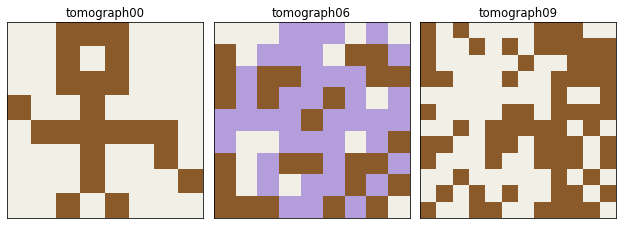

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def zeichne(ergebnis, titel, achse):
    werte = []
    for zeile in ergebnis:
        reihe = []
        for zeichen in zeile:
            if zeichen == '0':
                reihe.append(0)
            elif zeichen == '1':
                reihe.append(1)
            else:
                reihe.append(2)
        werte.append(reihe)
    farben = ListedColormap(['#f2efe6', '#8b5a2b', '#b39ddb'])   # leer, Holzspäne, nicht eindeutig
    achse.imshow(werte, cmap=farben, vmin=0, vmax=2)
    achse.set_title(titel)
    achse.set_xticks([])
    achse.set_yticks([])


fig, achsen = plt.subplots(1, 3, figsize=(9, 3.2))
zeichne(ergebnisse[0][0], 'tomograph00', achsen[0])
zeichne(ergebnisse[6][0], 'tomograph06', achsen[1])
zeichne(ergebnisse[9][0], 'tomograph09', achsen[2])
plt.tight_layout()
plt.show()

## Für Neugierige

**Warum nicht einfach alle Figuren durchprobieren?** Ein 12 × 12-Raster hat 144 Felder, also 2¹⁴⁴ Figuren, das ist eine Zahl mit
44 Stellen. Selbst der schnellste Computer würde damit nie fertig. Erst das frühe Erkennen von Sackgassen und das logische
Schließen machen das Ausprobieren schnell. Die Bewertungskriterien verlangen ausdrücklich solche Verbesserungen gegenüber reinem
Durchprobieren.

**Weitere Verbesserungen aus den Lösungshinweisen:**
- **Klug wählen, was man ausprobiert:** Statt des ersten offenen Feldes nimmt man ein Feld aus einer Linie, in der es nur wenige
  Möglichkeiten gibt (zum Beispiel fast alle Felder gefüllt oder fast alle leer). Dann führt ein Versuch seltener in die Irre.
- **Ganze Linien auf einmal:** Statt Feld für Feld probiert man alle Belegungen einer Linie mit der richtigen Anzahl gefüllter
  Felder. Bei 12 Feldern mit 6 gefüllten sind das 924 Möglichkeiten statt 2¹² = 4096.
- **Zufällige Reihenfolge:** Probiert man die Möglichkeiten in zufälliger Reihenfolge, findet man bei Eingaben mit sehr vielen
  Lösungen (wie `tomograph10.txt`) schneller eine.
- **Ganzzahlige lineare Optimierung (ILP):** Jedes Feld ist eine Variable, die 0 oder 1 sein kann, und jede Linie eine Gleichung
  „Summe der Variablen = Soll-Anzahl“. Fertige Programme (*Solver*) lösen solche Gleichungssysteme sehr schnell. Wie das mit
  MiniZinc geht, zeigt der letzte Abschnitt.

**Eine andere Vorgehensweise:** Man kann mit Backtracking auch **alle** passenden Figuren aufzählen und für jedes Feld mitschreiben,
welche Werte vorkommen. Das ist schnell, wenn es nur wenige Lösungen gibt, scheitert aber an `tomograph10.txt` mit sehr vielen
passenden Figuren.

## Zum Schluss: eine Lösung mit MiniZinc

Der Bibertomograph ist ein typisches **Constraint-Problem**: Jedes Feld ist eine Variable mit dem Wert 0 oder 1, und für jede
Sichtlinie gilt eine Bedingung „die Summe ist gleich der Soll-Anzahl“. Mit MiniZinc beschreibt man nur, **was** gelten soll. Das
logische Schließen und das Ausprobieren aus Schritt 3 und 4 übernimmt der Solver. Die Lösungshinweise nennen diesen Weg ebenfalls
(dort mit einem ILP-Solver) und verlangen dann aber, dass für **alle** Beispiele ein Ergebnis dokumentiert ist, auch für
`tomograph10.txt`.

Die MiniZinc-Blöcke unten sind **kein Python**: Kopiere sie in die MiniZinc IDE (oder in den
[MiniZinc Playground](https://play.minizinc.org/)) und führe sie dort aus.

#### Die Daten

Das Modell bekommt die Summen als Datendatei (`.dzn`). Die folgende Python-Zelle macht aus einer Beispieldatei den Inhalt der
Datendatei. Kopiere die Ausgabe in eine Datei `tomograph00.dzn`. `str(liste)` schreibt eine Python-Liste genau so, wie MiniZinc
ein Array erwartet.

In [ ]:
def als_dzn(dateiname):
    n, spalten, zeilen, blau, gelb = lies_eingabe(dateiname)
    text = 'n = ' + str(n) + ';\n'
    text = text + 'spalten = ' + str(spalten) + ';\n'
    text = text + 'zeilen = ' + str(zeilen) + ';\n'
    text = text + 'blau = ' + str(blau) + ';\n'
    text = text + 'gelb = ' + str(gelb) + ';'
    return text


print(als_dzn('beispieldaten/tomograph00.txt'))

n = 8;
spalten = [1, 1, 5, 6, 5, 1, 2, 1];
zeilen = [3, 2, 3, 2, 6, 2, 2, 2];
blau = [0, 0, 1, 3, 2, 3, 3, 1, 2, 3, 1, 2, 0, 1, 0];
gelb = [0, 0, 1, 0, 4, 2, 1, 3, 5, 3, 2, 1, 0, 0, 0];


#### Modell 1: eine passende Figur

Die Felder zählen wir hier ab 1, wie in MiniZinc üblich. Darum ändern sich die Formeln für die Diagonalen aus der Einleitung ein
wenig: Feld `(r, c)` liegt auf der blauen Linie `r + c − 1` und auf der gelben Linie `c − r + n`. Mit `sum(r, c in N where ...)`
addiert man über alle Felder, die die Bedingung erfüllen (wie bei `forall(a, b in ... where a < b)` im Arbeitsblatt *Zuordnen und
Planen*).

```minizinc
% ----- Daten (aus der .dzn-Datei) -----
int: n;
array[1..n] of int: spalten;          % gefüllte Felder je Spalte, von links nach rechts
array[1..n] of int: zeilen;           % je Zeile, von oben nach unten
array[1..2*n-1] of int: blau;         % je blauer Diagonale "/", beginnend oben links
array[1..2*n-1] of int: gelb;         % je gelber Diagonale "\", beginnend unten links

set of int: N = 1..n;

% ----- Entscheidungsvariablen -----
% x[r, c] = 1 heißt: Das Feld in Zeile r und Spalte c ist gefüllt
array[N, N] of var 0..1: x;

% ----- Bedingungen -----
constraint forall(c in N)(sum(r in N)(x[r, c]) = spalten[c]);
constraint forall(r in N)(sum(c in N)(x[r, c]) = zeilen[r]);
% blaue Diagonale d: alle Felder mit r + c = d + 1
constraint forall(d in 1..2*n-1)(sum(r, c in N where r + c = d + 1)(x[r, c]) = blau[d]);
% gelbe Diagonale d: alle Felder mit c - r + n = d
constraint forall(d in 1..2*n-1)(sum(r, c in N where c - r + n = d)(x[r, c]) = gelb[d]);

solve satisfy;

% Ausgabe gleich im Format einer Datendatei (für das zweite Modell)
output ["x = [|"] ++
       [show(x[r, c]) ++ if c < n then ", " elseif r < n then "\n     |" else "|];\n" endif | r, c in N];
```

Mit den Daten von `tomograph00.txt`:

**Ausgabe:**

```
x = [|0, 0, 1, 1, 1, 0, 0, 0
     |0, 0, 1, 0, 1, 0, 0, 0
     |0, 0, 1, 1, 1, 0, 0, 0
     |1, 0, 0, 1, 0, 0, 0, 0
     |0, 1, 1, 1, 1, 1, 1, 0
     |0, 0, 0, 1, 0, 0, 1, 0
     |0, 0, 0, 1, 0, 0, 0, 1
     |0, 0, 1, 0, 1, 0, 0, 0|];
----------
```

Das ist die Figur vom Aufgabenblatt. Der Solver braucht dafür (wie für jedes andere Beispiel) nur einen Bruchteil einer Sekunde.

#### Ist die Figur eindeutig?

Schalte im Konfigurationseditor **Print all solutions** ein: Dann gibt der Solver **alle** passenden Figuren aus, und unter
*Output solver statistics* steht ihre Anzahl (`nSolutions`).

| Beispiel | passende Figuren |
|---|---|
| tomograph00 | 1 |
| tomograph01 | 1 |
| tomograph02 | 1 |
| tomograph03 | 2 |
| tomograph04 | 5 |
| tomograph05 | 6 |
| tomograph06 | 12 |
| tomograph07 | 1 |
| tomograph08 | 1 |
| tomograph09 | 1 |
| tomograph10 | mehr als 1000 |

Genau eine Figur gibt es bei 00, 01, 02, 07, 08 und 09. Bei den Beispielen mit wenigen Figuren (03, 04, 05) kann man die
Fragezeichen noch von Hand finden: Man vergleicht alle ausgegebenen Figuren und setzt ein `?` überall, wo sie sich unterscheiden.
Bei `tomograph10.txt` geht das nicht mehr. Dafür gibt es ein zweites Modell.

#### Modell 2: die Fragezeichen

Ein Feld ist **nicht eindeutig**, wenn es eine zweite passende Figur gibt, die an dieser Stelle anders ist als eine schon bekannte
Figur `x`. Die Figur `x` liefert Modell 1, und zwar gleich im richtigen Format: Kopiere seine Ausgabe (ohne `----------`) ans Ende
der Datendatei.

Für jedes Feld `(i, j)` bekommt das Modell eine **eigene** zweite Figur. Darum hat `y` vier Indizes: Die ersten beiden sagen, für
welches Feld die Figur gedacht ist, die letzten beiden sind Zeile und Spalte wie bei `x`. Bei 12 × 12 sind das 144 Figuren mit je
144 Variablen.

Warum `maximize`? Mit `solve satisfy` dürfte der Solver einfach alle `frage[i, j]` auf `false` setzen. Er soll aber so viele
Fragezeichen wie möglich finden. Ein Fragezeichen kann er nur dort setzen, wo es eine passende zweite Figur mit anderem Wert
**wirklich gibt**. Bei der besten Lösung hat also jedes nicht eindeutige Feld ein Fragezeichen, und bei allen anderen Feldern hat
der Solver bewiesen, dass es keine solche Figur gibt.

```minizinc
% ----- Daten (aus der .dzn-Datei) -----
int: n;
array[1..n] of int: spalten;
array[1..n] of int: zeilen;
array[1..2*n-1] of int: blau;
array[1..2*n-1] of int: gelb;
set of int: N = 1..n;
array[N, N] of int: x;                % eine passende Figur (Ausgabe von Modell 1)

% ----- Entscheidungsvariablen -----
% y[i, j, r, c]: für jedes Feld (i, j) eine eigene zweite Figur
array[N, N, N, N] of var 0..1: y;
% frage[i, j]: Die zweite Figur für das Feld (i, j) hat dort einen anderen Wert als x
array[N, N] of var bool: frage;

% ----- Bedingungen -----
% jede zweite Figur passt zu allen Summen
constraint forall(i, j in N)(
    forall(c in N)(sum(r in N)(y[i, j, r, c]) = spalten[c]) /\
    forall(r in N)(sum(c in N)(y[i, j, r, c]) = zeilen[r]) /\
    forall(d in 1..2*n-1)(sum(r, c in N where r + c = d + 1)(y[i, j, r, c]) = blau[d]) /\
    forall(d in 1..2*n-1)(sum(r, c in N where c - r + n = d)(y[i, j, r, c]) = gelb[d])
);
constraint forall(i, j in N)(frage[i, j] = (y[i, j, i, j] != x[i, j]));

% möglichst viele Fragezeichen
solve maximize sum(frage);

output [if fix(frage[r, c]) then "?" else show(x[r, c]) endif ++ if c = n then "\n" else " " endif | r, c in N];
```

**Wähle als Solver Chuffed** (siehe *Wenn der Solver lange rechnet* im Arbeitsblatt *Zuordnen und Planen*): Gecode wird schon bei
`tomograph06.txt` in einer halben Minute nicht fertig. Mit Chuffed dauert selbst das größte Beispiel nur einige Sekunden. Zeigt die
IDE Zwischenlösungen mit weniger Fragezeichen, gilt die letzte vor `==========`.

Daten für `tomograph06.txt` (die Zeilen von `als_dzn` und darunter die Ausgabe von Modell 1):

```minizinc
n = 9;
spalten = [7, 3, 5, 6, 6, 5, 5, 6, 5];
zeilen = [3, 5, 8, 5, 6, 3, 7, 5, 6];
blau = [0, 1, 1, 3, 3, 5, 3, 5, 6, 5, 4, 1, 3, 4, 2, 2, 0];
gelb = [1, 2, 2, 1, 2, 4, 4, 7, 5, 4, 4, 4, 2, 3, 2, 1, 0];
x = [|0, 0, 0, 0, 1, 1, 0, 1, 0
     |1, 0, 1, 0, 1, 0, 1, 1, 0
     |1, 1, 1, 1, 1, 1, 0, 1, 1
     |1, 0, 1, 1, 0, 1, 1, 0, 0
     |1, 1, 0, 1, 1, 0, 1, 0, 1
     |0, 0, 0, 1, 1, 0, 0, 0, 1
     |1, 0, 1, 1, 1, 0, 1, 1, 1
     |1, 0, 0, 0, 0, 1, 1, 1, 1
     |1, 1, 1, 1, 0, 1, 0, 1, 0|];
```

**Ausgabe:**

```
0 0 0 ? ? ? 0 ? 0
1 0 ? ? ? 0 1 1 ?
1 ? 1 1 ? ? ? 1 1
1 ? 1 ? ? 1 ? 0 ?
? ? ? ? 1 ? ? ? ?
? 0 0 ? ? ? 0 ? 1
1 0 ? 1 1 ? 1 1 ?
1 0 ? 0 ? ? 1 ? 1
1 1 1 ? ? 1 ? 1 0
----------
==========
```

Und für das Beispiel mit sehr vielen passenden Figuren, `tomograph10.txt`:

**Ausgabe:**

```
0 ? ? ? ? ? ? ? ? ? ? 1
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
? ? ? ? ? ? ? ? ? ? ? ?
1 ? ? ? ? ? ? ? ? ? ? 0
----------
==========
```

Die Ergebnisse aller Beispiele stimmen mit Schritt 6 überein. Der Vergleich zeigt, was ein Solver kann und was nicht: Das Modell ist
viel kürzer als das Python-Programm, und man muss sich um die Suche nicht kümmern. Dafür muss man wissen, wie man die Frage nach den
Fragezeichen als Bedingungen ausdrückt, und welcher Solver dafür schnell genug ist.